# Lab 04 — Data Understanding & Exploratory Data Analysis (EDA)
**Tools:** Pandas · NumPy · Matplotlib

## Learning outcomes
By completing this notebook, you will be able to:
- inspect a dataset’s structure and variable types;
- summarize numerical data using descriptive statistics;
- identify missing values and investigate unusual observations;
- explore distributions and relationships using visualizations;
- communicate findings supported by evidence.

> **Instructions:** Complete each `TODO`, run the cells in order, and write brief interpretations. An unusual value is not automatically an error—investigate before deciding how to handle it.


## 1. Load the dataset

The Palmer Penguins dataset contains measurements of penguins from different species and islands. Load the CSV directly from the provided URL.

In [1]:
import pandas as pd
%pip install matplotlib
import numpy as np
import matplotlib.pyplot as plt

url = "https://huggingface.co/datasets/SIH/palmer-penguins/resolve/main/penguins.csv"

# TODO 1: Load the CSV into a DataFrame named df
df = pd.read_csv(url)

# TODO 2: Display the first five rows
df.head()


[notice] A new release of pip is available: 26.2.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,male,2007
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,female,2007
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,female,2007
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,female,2007


## 2. Understand the dataset

Inspect the dataset before analyzing it.

**Complete the tasks:**
1. Find the number of rows and columns.
2. Inspect column names and data types.
3. Display summary statistics.
4. Count observations in each penguin species.

In [2]:
# TODO 1: Display the number of rows and columns
print("Shape:", df.shape)

# TODO 2: Display the column names and data types
print("\nColumns and Data Types:\n", df.dtypes)

# TODO 3: Inspect non-missing counts and data types
print("\nDataFrame Info:")
df.info()

# TODO 4: Summarize numerical columns
display(df.describe())

# TODO 5: Count observations for each species
print("\nSpecies Counts:\n", df["species"].value_counts())

Shape: (344, 8)

Columns and Data Types:
 species                  str
island                   str
bill_length_mm       float64
bill_depth_mm        float64
flipper_length_mm    float64
body_mass_g          float64
sex                      str
year                   int64
dtype: object

DataFrame Info:
<class 'pandas.DataFrame'>
RangeIndex: 344 entries, 0 to 343
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   species            344 non-null    str    
 1   island             344 non-null    str    
 2   bill_length_mm     342 non-null    float64
 3   bill_depth_mm      342 non-null    float64
 4   flipper_length_mm  342 non-null    float64
 5   body_mass_g        342 non-null    float64
 6   sex                333 non-null    str    
 7   year               344 non-null    int64  
dtypes: float64(4), int64(1), str(3)
memory usage: 21.6 KB


,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,year
count,342.000000,342.000000,342.000000,342.000000,344.000000
mean,43.921930,17.151170,200.915205,4201.754386,2008.029070
std,5.459584,1.974793,14.061714,801.954536,0.818356
min,32.100000,13.100000,172.000000,2700.000000,2007.000000
25%,39.225000,15.600000,190.000000,3550.000000,2007.000000
50%,44.450000,17.300000,197.000000,4050.000000,2008.000000
75%,48.500000,18.700000,213.000000,4750.000000,2009.000000
max,59.600000,21.500000,231.000000,6300.000000,2009.000000



Species Counts:
 species
Adelie       152
Gentoo       124
Chinstrap     68
Name: count, dtype: int64


**Interpret your results**

- How many observations and variables are in the dataset?
- Which variables are numerical, and which are categorical?
- Are the species represented equally?

Write your answers below.

**Your observations:**  
TODO: Write 2–3 sentences here.

## 3. Assess data quality

Missing values can affect summaries and visualizations. First, identify where they occur; do not remove rows automatically.

In [3]:
# TODO 1: Count missing values in each column
missing_counts = df.isnull().sum()
display(missing_counts)

# TODO 2: Calculate the percentage of missing values in each column
missing_percent = (df.isnull().sum() / len(df)) * 100
display(missing_percent.round(2))

# TODO 3: Display rows that contain at least one missing value
rows_with_missing = df[df.isnull().any(axis=1)]
display(rows_with_missing.head())

species               0
island                0
bill_length_mm        2
bill_depth_mm         2
flipper_length_mm     2
body_mass_g           2
sex                  11
year                  0
dtype: int64

species              0.00
island               0.00
bill_length_mm       0.58
bill_depth_mm        0.58
flipper_length_mm    0.58
body_mass_g          0.58
sex                  3.20
year                 0.00
dtype: float64

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex,year
3,Adelie,Torgersen,NaN,NaN,NaN,NaN,NaN,2007
8,Adelie,Torgersen,34.1,18.1,193.0,3475.0,NaN,2007
9,Adelie,Torgersen,42.0,20.2,190.0,4250.0,NaN,2007
10,Adelie,Torgersen,37.8,17.1,186.0,3300.0,NaN,2007
11,Adelie,Torgersen,37.8,17.3,180.0,3700.0,NaN,2007


**Interpret your results**

- Which columns contain missing values?
- How might missing values affect your analysis?
- What additional information would help you decide how to handle them?

**Your observations:**  
TODO: Write 2–3 sentences here.

## 4. Explore numerical variables

Use descriptive statistics to understand the center and spread of a variable. In this section, focus on `body_mass_g`.

In [4]:
# Select body mass and exclude missing values
body_mass = df["body_mass_g"].dropna()

# TODO 1: Calculate the mean and median using NumPy
mean_mass = np.mean(body_mass)
median_mass = np.median(body_mass)
print("Mean:", mean_mass)
print("Median:", median_mass)

# TODO 2: Find the minimum and maximum
min_mass = body_mass.min()
max_mass = body_mass.max()
print("Minimum:", min_mass)
print("Maximum:", max_mass)

# TODO 3: Calculate standard deviation and quartiles
std_mass = np.std(body_mass)
quartiles_mass = np.percentile(body_mass, [25, 50, 75])
print("Standard Deviation:", std_mass)
print("Quartiles (25%, 50%, 75%):", quartiles_mass)

# TODO 4: Display the five smallest and five largest body-mass values
print("\n5 Smallest body-mass values:\n", body_mass.nsmallest(5))
print("\n5 Largest body-mass values:\n", body_mass.nlargest(5))

Mean: 4201.754385964912
Median: 4050.0
Minimum: 2700.0
Maximum: 6300.0
Standard Deviation: 800.781229238452
Quartiles (25%, 50%, 75%): [3550. 4050. 4750.]

5 Smallest body-mass values:
 314    2700.0
58     2850.0
64     2850.0
54     2900.0
98     2900.0
Name: body_mass_g, dtype: float64

5 Largest body-mass values:
 169    6300.0
185    6050.0
229    6000.0
269    6000.0
231    5950.0
Name: body_mass_g, dtype: float64


**Interpret your results**

- How different are the mean and median?
- What do the minimum and maximum tell you?
- Do any values deserve further investigation? Explain why.

**Your observations:**  
TODO: Write 2–3 sentences here.

## 5. Visualize distributions

A histogram helps reveal the shape of a numerical distribution. Create a histogram of body mass and label it clearly.

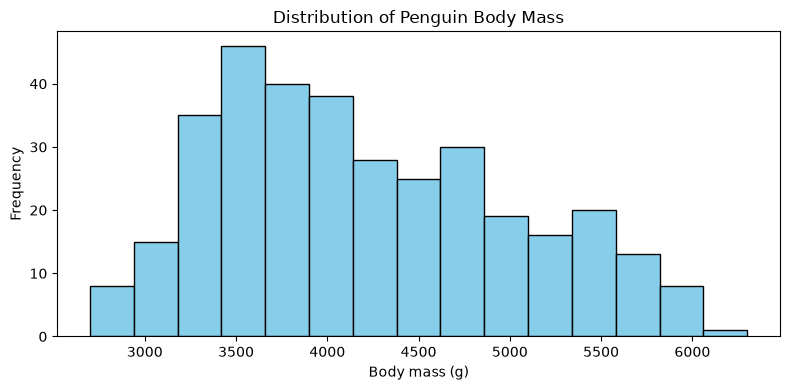

In [5]:
# Missing values are excluded for this histogram
mass_values = df["body_mass_g"].dropna()

plt.figure(figsize=(8, 4))

# TODO: Create a histogram
plt.hist(mass_values, bins=15, edgecolor="black", color="skyblue")

plt.xlabel("Body mass (g)")
plt.ylabel("Frequency")
plt.title("Distribution of Penguin Body Mass")
plt.tight_layout()
plt.show()

**Interpret the histogram**

- Where are most observations concentrated?
- Does the distribution appear symmetric or skewed?
- Are there any values that may need further investigation?

**Your interpretation:**  
TODO: Write 2–3 sentences here.

## 6. Explore relationships

A scatter plot helps investigate how two numerical variables vary together. Explore flipper length and body mass.

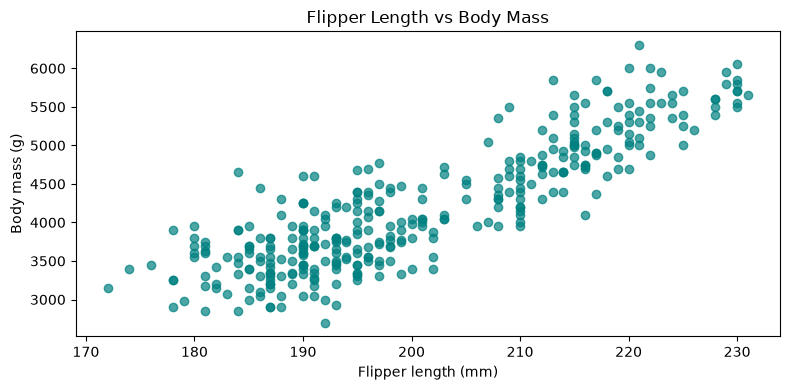

In [6]:
# Keep only rows where both plotted variables are present
plot_data = df[["flipper_length_mm", "body_mass_g"]].dropna()

plt.figure(figsize=(8, 4))

# TODO: Create a scatter plot
plt.scatter(plot_data["flipper_length_mm"], plot_data["body_mass_g"], alpha=0.7, color="teal")

plt.xlabel("Flipper length (mm)")
plt.ylabel("Body mass (g)")
plt.title("Flipper Length vs Body Mass")
plt.tight_layout()
plt.show()

**Interpret the scatter plot**

- Does the plot suggest a positive, negative, or unclear relationship?
- Do you see clusters or points far from the main pattern?
- Does a relationship between two variables prove that one causes the other?

**Your interpretation:**  
TODO: Write 2–3 sentences here.

## 7. Compare groups

Compare average body mass across penguin species. Grouped summaries help reveal differences between categories.

In [7]:
# TODO 1: Calculate mean body mass for each species
mean_by_species = df.groupby("species")["body_mass_g"].mean()
display(mean_by_species)

# TODO 2: Calculate median body mass for each species
median_by_species = df.groupby("species")["body_mass_g"].median()
display(median_by_species)

species
Adelie       3700.662252
Chinstrap    3733.088235
Gentoo       5076.016260
Name: body_mass_g, dtype: float64

species
Adelie       3700.0
Chinstrap    3700.0
Gentoo       5000.0
Name: body_mass_g, dtype: float64

**Interpret your results**

- Which species has the highest mean body mass?
- Does the group comparison tell the same story as the overall histogram?
- What limitation should you keep in mind when comparing group averages?

**Your observations:**  
TODO: Write 2–3 sentences here.

## 8. Investigate potential outliers

A box plot can highlight observations far from the central range. Such observations are potential outliers, not automatically errors.

C:\Users\Sadat\AppData\Local\Temp\ipykernel_7968\2244061802.py:7: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(mass_values, vert=False)


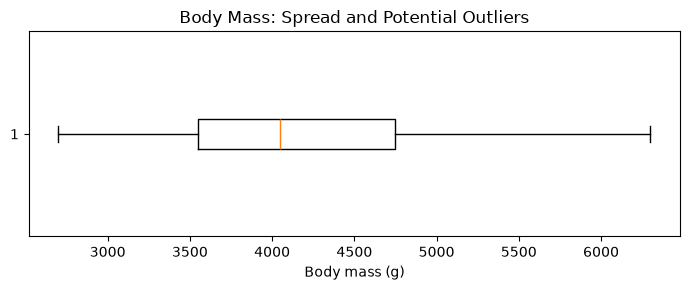

In [8]:
# Exclude missing body-mass values before plotting
mass_values = df["body_mass_g"].dropna()

plt.figure(figsize=(7, 3))

# TODO: Create a box plot
plt.boxplot(mass_values, vert=False)

plt.xlabel("Body mass (g)")
plt.title("Body Mass: Spread and Potential Outliers")
plt.tight_layout()
plt.show()

**Key principle:** EDA is not just producing statistics and plots. It is using them to understand the data, ask better questions, and make careful, evidence-based decisions.